In [8]:
import sys
print(sys.executable)

c:\Users\Hp\AppData\Local\Programs\Python\Python311\python.exe


# **Lab Task 01**

## (a) Task 1: Lowercasing Basics and Its Drawbacks

In [9]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

corpus = [
    "Apple released a new product in the US.",
    "I ate an apple after lunch.",
    "APPLE shares rose sharply today.",
    "The US team won the match.",
    "Many students study in the us every day.",
    "Apple stores are popular around the world.",
    "She bought a red apple from the market.",
    "The APPLE company announced new services.",
    "US universities welcome international students.",
    "Please send the package to us before Friday.",
    "I like Apple devices for study.",
    "An apple contains useful nutrients."
]

def tokenize(text):
    return re.findall(r"\b[\w']+\b", text)

tokens_before = [word for sentence in corpus for word in tokenize(sentence)]
vocab_before = set(tokens_before)

lower_corpus = [sentence.lower() for sentence in corpus]
tokens_after = [word for sentence in lower_corpus for word in tokenize(sentence)]
vocab_after = set(tokens_after)

print("Vocabulary size before lowercasing:", len(vocab_before))
print("Vocabulary size after lowercasing:", len(vocab_after))
print("\nVocabulary before:")
print(sorted(vocab_before))
print("\nVocabulary after:")
print(sorted(vocab_after))

examples = pd.DataFrame({
    "Original": [
        "US students arrived early.",
        "Apple released a new product.",
        "The company sent the report to US."
    ],
    "After Lowercasing": [
        "us students arrived early.",
        "apple released a new product.",
        "the company sent the report to us."
    ],
    "Possible Ambiguity": [
        "US = United States, us = pronoun",
        "Apple = company, apple = fruit",
        "US = United States, us = pronoun"
    ]
})

display(examples)

print("\nShort explanation:")
print("""Lowercasing reduces vocabulary size and makes matching words easier, but it can remove useful case information.
NER can be harmed because capitalization helps identify names, organizations and locations. Sentiment analysis can lose
signals in texts where capitalization expresses emphasis. Search can also be affected when a query distinguishes a
proper name from an ordinary word, such as Apple the company versus apple the fruit. Therefore, lowercasing is useful
for many NLP pipelines, but it should not always be applied blindly.""")

Matplotlib is building the font cache; this may take a moment.


Vocabulary size before lowercasing: 58
Vocabulary size after lowercasing: 53

Vocabulary before:
['APPLE', 'An', 'Apple', 'Friday', 'I', 'Many', 'Please', 'She', 'The', 'US', 'a', 'after', 'an', 'announced', 'apple', 'are', 'around', 'ate', 'before', 'bought', 'company', 'contains', 'day', 'devices', 'every', 'for', 'from', 'in', 'international', 'like', 'lunch', 'market', 'match', 'new', 'nutrients', 'package', 'popular', 'product', 'red', 'released', 'rose', 'send', 'services', 'shares', 'sharply', 'stores', 'students', 'study', 'team', 'the', 'to', 'today', 'universities', 'us', 'useful', 'welcome', 'won', 'world']

Vocabulary after:
['a', 'after', 'an', 'announced', 'apple', 'are', 'around', 'ate', 'before', 'bought', 'company', 'contains', 'day', 'devices', 'every', 'for', 'friday', 'from', 'i', 'in', 'international', 'like', 'lunch', 'many', 'market', 'match', 'new', 'nutrients', 'package', 'please', 'popular', 'product', 'red', 'released', 'rose', 'send', 'services', 'shares', '

,Original,After Lowercasing,Possible Ambiguity
0,US students arrived early.,us students arrived early.,"US = United States, us = pronoun"
1,Apple released a new product.,apple released a new product.,"Apple = company, apple = fruit"
2,The company sent the report to US.,the company sent the report to us.,"US = United States, us = pronoun"



Short explanation:
Lowercasing reduces vocabulary size and makes matching words easier, but it can remove useful case information.
NER can be harmed because capitalization helps identify names, organizations and locations. Sentiment analysis can lose
signals in texts where capitalization expresses emphasis. Search can also be affected when a query distinguishes a
proper name from an ordinary word, such as Apple the company versus apple the fruit. Therefore, lowercasing is useful
for many NLP pipelines, but it should not always be applied blindly.


## (b) Task 2: Noise Removal Pipeline

In [6]:
import re
import pandas as pd

noisy_data = [
    "I LOVE this phone!!!  Visit https://example.com @techuser #AmazingDeal",
    "<p>Great product!!!</p> Check www.shop.com now. @maryam #shopping ",
    "Worst service ever!!!  https://service.com @support #badservice",
    "Amazing quality   and fast delivery!!! @store #recommended",
    "<div>Very useful product</div>  Visit http://product.com",
    "The price is $100!!! #Deal @seller https://shop.pk",
    "I bought C++ programming book!!!  @bookstore #coding",
    "Not happy with delivery...  www.delivery.com @company",
    "<b>Excellent support</b>!!! #support  https://help.com",
    "This is okay, but packaging was poor. @seller #review",
    "Five stars!!!  Visit https://review.com #happy",
    "The app crashed again!!!  @developer #bug",
    "<p>Fast shipping and nice packaging.</p> ",
    "Would buy again!!! @shopper #recommended https://buy.com",
    "The product is good!!! Price is $100. @seller #value"
]

def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)

def remove_html(text):
    return re.sub(r"<[^>]+>", "", text)

def handle_mentions_hashtags(text):
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return text

def remove_punctuation(text):
    return re.sub(r"[^\w\s$+]", "", text)

def remove_extra_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

def clean_text(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = handle_mentions_hashtags(text)
    text = remove_punctuation(text)
    text = remove_extra_whitespace(text)
    return text

cleaned_data = [clean_text(text) for text in noisy_data]

comparison = pd.DataFrame({
    "Before": noisy_data[:5],
    "After": cleaned_data[:5]
})
display(comparison)

print("Examples where cleaning can go too far:")
print("1. C++ can become C++ only if '+' is preserved; a generic punctuation rule may damage it.")
print("2. $100 can lose the '$' symbol if currency symbols are removed.")
print("3. Hashtags may lose their original boundary information when '#' is removed.")

def clean_text_changed_order(text):
    text = remove_punctuation(text)
    text = handle_mentions_hashtags(text)
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_extra_whitespace(text)
    return text

order_results = pd.DataFrame({
    "Original": noisy_data[:5],
    "Normal Order": [clean_text(x) for x in noisy_data[:5]],
    "Changed Order": [clean_text_changed_order(x) for x in noisy_data[:5]]
})
display(order_results)

print("Ordering effect:")
print("The order can change the output when one operation depends on text removed by another operation.")
print("For example, removing punctuation before hashtag handling can destroy the '#' marker.")
print("URL and HTML removal are safest before punctuation and whitespace normalization.")

,Before,After
0,I LOVE this phone!!! Visit https://example.co...,I LOVE this phone Visit AmazingDeal
1,<p>Great product!!!</p> Check www.shop.com now...,Great product Check now shopping
2,Worst service ever!!! https://service.com @su...,Worst service ever badservice
3,Amazing quality and fast delivery!!! @store ...,Amazing quality and fast delivery recommended
4,<div>Very useful product</div> Visit http://p...,Very useful product Visit


Examples where cleaning can go too far:
1. C++ can become C++ only if '+' is preserved; a generic punctuation rule may damage it.
2. $100 can lose the '$' symbol if currency symbols are removed.
3. Hashtags may lose their original boundary information when '#' is removed.


,Original,Normal Order,Changed Order
0,I LOVE this phone!!! Visit https://example.co...,I LOVE this phone Visit AmazingDeal,I LOVE this phone Visit httpsexamplecom techus...
1,<p>Great product!!!</p> Check www.shop.com now...,Great product Check now shopping,pGreat productp Check wwwshopcom now maryam sh...
2,Worst service ever!!! https://service.com @su...,Worst service ever badservice,Worst service ever httpsservicecom support bad...
3,Amazing quality and fast delivery!!! @store ...,Amazing quality and fast delivery recommended,Amazing quality and fast delivery store recomm...
4,<div>Very useful product</div> Visit http://p...,Very useful product Visit,divVery useful productdiv Visit httpproductcom


Ordering effect:
The order can change the output when one operation depends on text removed by another operation.
For example, removing punctuation before hashtag handling can destroy the '#' marker.
URL and HTML removal are safest before punctuation and whitespace normalization.


## (c) Task 3: Stop-Word Removal and Its Effect on Vocabulary

First 20 NLTK English stop-words:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total number of stop-words: 198


,Measure,Before,After
0,Token count,102.0,42.0
1,Vocabulary size,45.0,28.0
2,Average sentence length,10.2,4.2


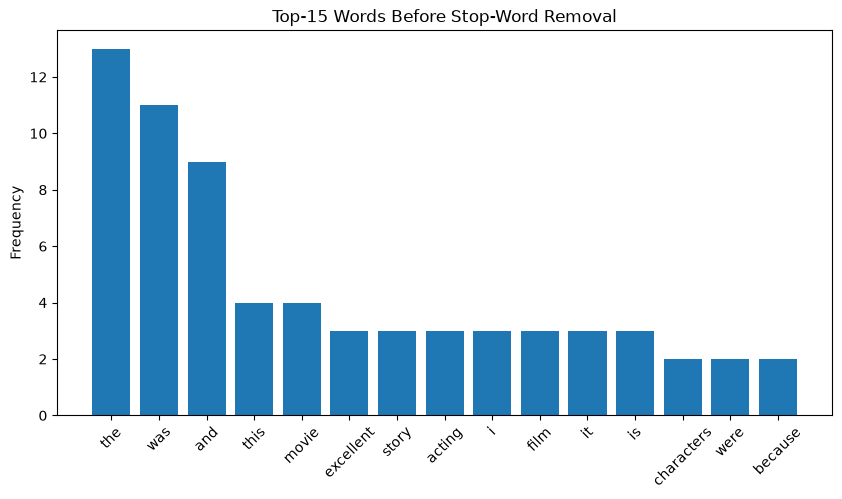

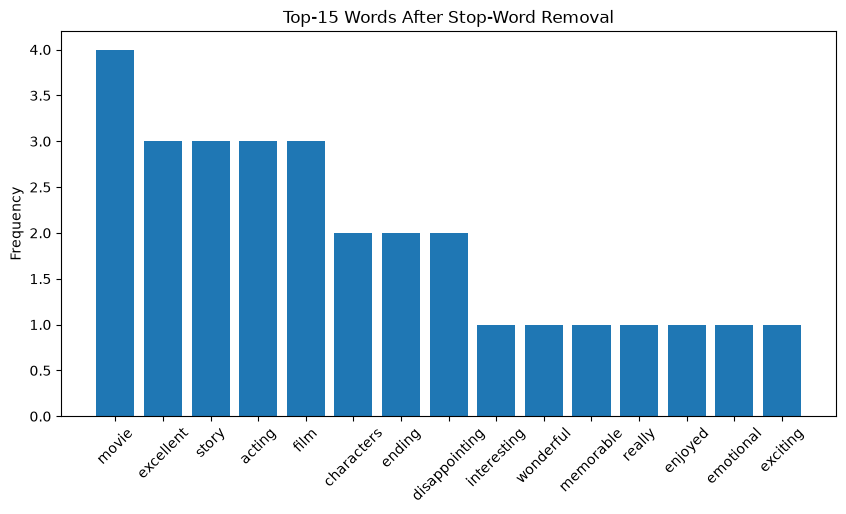

,Word,Decision,Justification
0,movie,Remove,Keep because it identifies the review domain.
1,film,Remove,Keep because it is a useful domain term.
2,acting,Keep,Keep because it describes an important movie a...
3,characters,Keep,Keep because it describes a movie component.
4,story,Keep,Keep because it carries topical meaning.
5,ending,Keep,Keep because it can be important for review an...
6,boring,Keep,Keep because it carries sentiment.
7,excellent,Keep,Keep because it carries positive sentiment.
8,disappointing,Keep,Keep because it carries negative sentiment.
9,amazing,Keep,Keep because it carries strong positive sentim...


Custom stop-word strategy:
Negation words such as not, no and never are retained because removing them can reverse sentiment.
Domain-specific terms may be removed only when they add little information for the particular task.


In [12]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
english_stopwords = set(stopwords.words("english"))

print("First 20 NLTK English stop-words:")
print(sorted(english_stopwords)[:20])
print("Total number of stop-words:", len(english_stopwords))

reviews = [
    "This movie was excellent and the story was very interesting.",
    "The acting was wonderful and the characters were memorable.",
    "I really enjoyed this film because it was emotional and exciting.",
    "The movie had a slow beginning but the ending was excellent.",
    "This was a disappointing film and the story was weak.",
    "The acting was poor and the characters were not convincing.",
    "I did not enjoy the movie because it was boring and predictable.",
    "The film was too long and the ending was disappointing.",
    "This movie is amazing and I would watch it again.",
    "The story is beautiful and the acting is excellent."
]

def word_tokens(text):
    return re.findall(r"\b[a-zA-Z]+\b", text.lower())

all_tokens = [token for text in reviews for token in word_tokens(text)]
filtered_tokens = [token for token in all_tokens if token not in english_stopwords]

sent_lengths_before = [len(word_tokens(x)) for x in reviews]
sent_lengths_after = [
    len([w for w in word_tokens(x) if w not in english_stopwords])
    for x in reviews
]

summary = pd.DataFrame({
    "Measure": ["Token count", "Vocabulary size", "Average sentence length"],
    "Before": [
        len(all_tokens),
        len(set(all_tokens)),
        sum(sent_lengths_before) / len(sent_lengths_before)
    ],
    "After": [
        len(filtered_tokens),
        len(set(filtered_tokens)),
        sum(sent_lengths_after) / len(sent_lengths_after)
    ]
})
display(summary)

before_freq = Counter(all_tokens).most_common(15)
after_freq = Counter(filtered_tokens).most_common(15)

plt.figure(figsize=(10, 5))
plt.bar([x[0] for x in before_freq], [x[1] for x in before_freq])
plt.title("Top-15 Words Before Stop-Word Removal")
plt.xticks(rotation=45)
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar([x[0] for x in after_freq], [x[1] for x in after_freq])
plt.title("Top-15 Words After Stop-Word Removal")
plt.xticks(rotation=45)
plt.ylabel("Frequency")
plt.show()

domain_words = {
    "movie": "Keep because it identifies the review domain.",
    "film": "Keep because it is a useful domain term.",
    "acting": "Keep because it describes an important movie attribute.",
    "characters": "Keep because it describes a movie component.",
    "story": "Keep because it carries topical meaning.",
    "ending": "Keep because it can be important for review analysis.",
    "boring": "Keep because it carries sentiment.",
    "excellent": "Keep because it carries positive sentiment.",
    "disappointing": "Keep because it carries negative sentiment.",
    "amazing": "Keep because it carries strong positive sentiment."
}

custom_stopwords = english_stopwords - {"not", "no", "never"} | {"movie", "film"}

custom_table = pd.DataFrame({
    "Word": list(domain_words.keys()),
    "Decision": ["Keep" if w not in custom_stopwords else "Remove" for w in domain_words],
    "Justification": list(domain_words.values())
})
display(custom_table)

print("Custom stop-word strategy:")
print("Negation words such as not, no and never are retained because removing them can reverse sentiment.")
print("Domain-specific terms may be removed only when they add little information for the particular task.")

## (d) Task 4: Risks of Stop-Word Removal

In [13]:
import re
import pandas as pd

sentences = [
    "This product is not good.",
    "I am never happy with this service.",
    "There is no problem with the order.",
    "The movie is not interesting.",
    "I will never recommend this product."
]

def remove_stopwords(text, stopword_set):
    return " ".join(
        word for word in re.findall(r"\b[a-zA-Z]+\b", text.lower())
        if word not in stopword_set
    )

regular_removed = [remove_stopwords(x, english_stopwords) for x in sentences]
safe_stopwords = english_stopwords - {"not", "no", "never"}
safe_removed = [remove_stopwords(x, safe_stopwords) for x in sentences]

sentiment_check = pd.DataFrame({
    "Original": sentences,
    "Regular Stop-Word Removal": regular_removed,
    "Safe Removal": safe_removed
})
display(sentiment_check)

print("Sentiment observation:")
print("Regular stop-word removal can delete negation words such as not, no and never.")
print("For example, 'not good' becomes 'good', which can reverse the sentiment.")
print("A safer strategy is to keep important negation words.")

translation_sentences = [
    "I do not like this product.",
    "The order has not arrived yet.",
    "There is no problem with my payment."
]

translation_reduced = [remove_stopwords(x, english_stopwords) for x in translation_sentences]
translation_table = pd.DataFrame({
    "English Original": translation_sentences,
    "English After Stop-Word Removal": translation_reduced
})
display(translation_table)

print("Machine Translation:")
print("The reduced versions remove grammatical words and negation, so a translator can receive incomplete or distorted meaning.")
print("The original sentences preserve the grammatical information required for a reliable English-to-Urdu translation.")

chatbot_queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "Can I cancel my order?",
    "Why has my payment not arrived?",
    "Where can I find my refund?"
]

chatbot_reduced = [remove_stopwords(x, english_stopwords) for x in chatbot_queries]
chatbot_table = pd.DataFrame({
    "Original Query": chatbot_queries,
    "After Stop-Word Removal": chatbot_reduced
})
display(chatbot_table)

print("Chatbot intent observation:")
print("Stop-word removal can remove words that identify the intent, especially negation and question structure.")
print("For chatbot systems, intent classification should normally use the original text or a carefully designed preprocessing strategy.")

,Original,Regular Stop-Word Removal,Safe Removal
0,This product is not good.,product good,product not good
1,I am never happy with this service.,never happy service,never happy service
2,There is no problem with the order.,problem order,no problem order
3,The movie is not interesting.,movie interesting,movie not interesting
4,I will never recommend this product.,never recommend product,never recommend product


Sentiment observation:
Regular stop-word removal can delete negation words such as not, no and never.
For example, 'not good' becomes 'good', which can reverse the sentiment.
A safer strategy is to keep important negation words.


,English Original,English After Stop-Word Removal
0,I do not like this product.,like product
1,The order has not arrived yet.,order arrived yet
2,There is no problem with my payment.,problem payment


Machine Translation:
The reduced versions remove grammatical words and negation, so a translator can receive incomplete or distorted meaning.
The original sentences preserve the grammatical information required for a reliable English-to-Urdu translation.


,Original Query,After Stop-Word Removal
0,How to not be charged?,charged
1,What is the status of my order?,status order
2,Can I cancel my order?,cancel order
3,Why has my payment not arrived?,payment arrived
4,Where can I find my refund?,find refund


Chatbot intent observation:
Stop-word removal can remove words that identify the intent, especially negation and question structure.
For chatbot systems, intent classification should normally use the original text or a carefully designed preprocessing strategy.


## (e) Task 5: Hands-On with the Porter Stemmer

In [14]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer("english")

words = [
    "running", "runs", "runner", "studies", "studying", "studied",
    "happily", "happiness", "generalization", "generalized", "better",
    "best", "was", "walking", "walked", "connection", "connected",
    "organization", "organizing", "universities", "university",
    "universe", "relational", "relationally", "cats", "ponies",
    "caresses", "caress", "agreed", "agreement", "easily", "fairly",
    "relating", "triplicate", "friendship", "friendships"
]

stems = [porter.stem(word) for word in words]

correct_expected = {
    "running": "run",
    "runs": "run",
    "studies": "studi",
    "studying": "studi",
    "studied": "studi",
    "happily": "happili",
    "generalization": "gener",
    "generalized": "gener",
    "better": "better",
    "was": "wa"
}

result = pd.DataFrame({
    "Word": words,
    "Stem": stems
})
result["Correct/Incorrect"] = result.apply(
    lambda row: "Expected Porter behavior" if row["Word"] in correct_expected and row["Stem"] == correct_expected[row["Word"]]
    else "Check linguistic meaning",
    axis=1
)
display(result)

over_stemming = pd.DataFrame({
    "Words": ["university / universe", "organization / organ", "relational / relate"],
    "Issue": [
        "Different meanings may receive similar shortened stems.",
        "Unrelated meanings can become too similar after aggressive stemming.",
        "Morphological shortening can remove useful distinctions."
    ]
})
display(over_stemming)

under_stemming = pd.DataFrame({
    "Related Words": ["analysis / analyze", "goose / geese", "better / good"],
    "Issue": [
        "Related concepts can remain different because stemming is rule-based.",
        "Irregular forms are not always normalized to one linguistic root.",
        "A stemmer does not perform true vocabulary-based lemmatization."
    ]
})
display(under_stemming)

snowball_stems = [snowball.stem(word) for word in words]
comparison = pd.DataFrame({
    "Word": words,
    "Porter": stems,
    "Snowball": snowball_stems
})
different = comparison[comparison["Porter"] != comparison["Snowball"]]
print("Words where Porter and Snowball differ:")
display(different)

,Word,Stem,Correct/Incorrect
0,running,run,Expected Porter behavior
1,runs,run,Expected Porter behavior
2,runner,runner,Check linguistic meaning
3,studies,studi,Expected Porter behavior
4,studying,studi,Expected Porter behavior
5,studied,studi,Expected Porter behavior
6,happily,happili,Expected Porter behavior
7,happiness,happi,Check linguistic meaning
8,generalization,gener,Expected Porter behavior
9,generalized,gener,Expected Porter behavior


,Words,Issue
0,university / universe,Different meanings may receive similar shorten...
1,organization / organ,Unrelated meanings can become too similar afte...
2,relational / relate,Morphological shortening can remove useful dis...


,Related Words,Issue
0,analysis / analyze,Related concepts can remain different because ...
1,goose / geese,Irregular forms are not always normalized to o...
2,better / good,A stemmer does not perform true vocabulary-bas...


Words where Porter and Snowball differ:


,Word,Porter,Snowball
8,generalization,gener,general
9,generalized,gener,general
12,was,wa,was
23,relationally,relat,relate
31,fairly,fairli,fair


## (f) Task 6: Lemmatization (spaCy) vs. Stemming

In [15]:
import sys
import subprocess
import importlib.util
import time
import re
import pandas as pd
from nltk.stem import PorterStemmer

if importlib.util.find_spec("spacy") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "spacy", "-q"])

import spacy

try:
    nlp = spacy.load("en_core_web_sm")
except Exception:
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
    nlp = spacy.load("en_core_web_sm")

paragraph = """Natural language processing helps computers understand human language. 
Students use NLP to analyze documents, classify text, detect names, and study opinions.
Modern systems can process large collections of reviews, news articles, messages, and web pages.
Tokenization divides text into useful units while part of speech tagging identifies grammatical roles.
Lemmatization uses these grammatical roles to find meaningful dictionary forms.
For example, better can be mapped to good and was can be mapped to be.
Stemming is faster because it usually removes word endings without understanding the complete context.
However, stemming can create forms that are not real words and can sometimes merge words with different meanings.
In practical applications, preprocessing should be selected according to the goal of the NLP system.
Search systems may benefit from normalization, while information extraction may need capitalization and detailed linguistic information.
Sentiment analysis also needs care because negation can change the meaning of an entire sentence.
Good preprocessing therefore balances simplicity, speed, and preservation of useful information."""

doc = nlp(paragraph)
tokens = [token for token in doc if not token.is_space and token.is_alpha]

porter = PorterStemmer()
comparison = pd.DataFrame({
    "Token": [token.text for token in tokens],
    "POS": [token.pos_ for token in tokens],
    "Stem": [porter.stem(token.text) for token in tokens],
    "Lemma": [token.lemma_ for token in tokens]
})
display(comparison.head(50))

print("Number of alphabetic tokens:", len(tokens))
print("Number of words:", len(tokens))

examples = comparison[
    comparison["Token"].str.lower().isin(["better", "was", "running", "students", "studies"])
]
display(examples)

print("Why POS matters:")
print("A lemma depends on the grammatical role of a word. The POS tag helps spaCy decide whether a form is a noun, verb, adjective, or another category.")
print("This is why lemmatization can produce meaningful dictionary forms while a stemmer mainly applies word-ending rules.")

text_for_speed = [token.text for token in tokens] * 100

start = time.time()
porter_results = [porter.stem(word) for word in text_for_speed]
stemming_time = time.time() - start

start = time.time()
spacy_results = [token.lemma_ for token in nlp(" ".join(text_for_speed)) if token.is_alpha]
lemmatization_time = time.time() - start

speed_table = pd.DataFrame({
    "Method": ["Porter Stemming", "spaCy Lemmatization"],
    "Time (seconds)": [stemming_time, lemmatization_time]
})
display(speed_table)

print("Choice:")
print("Use stemming when speed and simple normalization are more important than linguistic accuracy.")
print("Use lemmatization when meaningful dictionary forms and grammatical context are important.")

,Token,POS,Stem,Lemma
0,Natural,ADJ,natur,natural
1,language,NOUN,languag,language
2,processing,NOUN,process,processing
3,helps,VERB,help,help
4,computers,NOUN,comput,computer
5,understand,VERB,understand,understand
6,human,ADJ,human,human
7,language,NOUN,languag,language
8,Students,NOUN,student,student
9,use,VERB,use,use


Number of alphabetic tokens: 163
Number of words: 163


,Token,POS,Stem,Lemma
8,Students,NOUN,student,student
61,better,ADV,better,well
68,was,AUX,wa,be


Why POS matters:
A lemma depends on the grammatical role of a word. The POS tag helps spaCy decide whether a form is a noun, verb, adjective, or another category.
This is why lemmatization can produce meaningful dictionary forms while a stemmer mainly applies word-ending rules.


,Method,Time (seconds)
0,Porter Stemming,1.067843
1,spaCy Lemmatization,13.021989


Choice:
Use stemming when speed and simple normalization are more important than linguistic accuracy.
Use lemmatization when meaningful dictionary forms and grammatical context are important.


## (g) Task 7: Preprocessing Pipeline

In [16]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer

positive_texts = [
    "This product is excellent and I love the quality.",
    "The service was amazing and very helpful.",
    "I enjoyed the fast delivery and good packaging.",
    "The movie was wonderful and highly entertaining.",
    "This app is useful, simple, and reliable.",
    "The customer support was friendly and efficient.",
    "I am happy with this purchase and would recommend it.",
    "The quality is great and the price is reasonable.",
    "This was a fantastic experience from start to finish.",
    "The new design looks beautiful and works perfectly."
]

negative_texts = [
    "This product is terrible and I hate the quality.",
    "The service was awful and very disappointing.",
    "I disliked the slow delivery and poor packaging.",
    "The movie was boring and badly written.",
    "This app is confusing, slow, and unreliable.",
    "The customer support was rude and inefficient.",
    "I am unhappy with this purchase and would not recommend it.",
    "The quality is poor and the price is unreasonable.",
    "This was a horrible experience from start to finish.",
    "The new design looks bad and works poorly."
]

documents = []
labels = []

for i in range(3):
    for text in positive_texts:
        documents.append(text)
        labels.append(1)
    for text in negative_texts:
        documents.append(text)
        labels.append(0)

data = pd.DataFrame({"text": documents, "label": labels})
print("Number of documents:", len(data))

porter = PorterStemmer()

def basic_noise_removal(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = handle_mentions_hashtags(text)
    text = remove_extra_whitespace(text)
    return text

def pipeline(text, lowercase=True, remove_stops=False, stem=False, lemma=False):
    text = basic_noise_removal(text)
    if lowercase:
        text = text.lower()
    tokens = re.findall(r"\b[a-zA-Z]+\b", text)
    if remove_stops:
        tokens = [w for w in tokens if w not in english_stopwords]
    if stem:
        tokens = [porter.stem(w) for w in tokens]
    if lemma:
        tokens = [t.lemma_ for t in nlp(" ".join(tokens)) if t.is_alpha]
    return tokens

configs = {
    "Lowercase only": {"lowercase": True, "remove_stops": False, "stem": False, "lemma": False},
    "Lowercase + stop-words": {"lowercase": True, "remove_stops": True, "stem": False, "lemma": False},
    "Lowercase + stemming": {"lowercase": True, "remove_stops": False, "stem": True, "lemma": False},
    "Lowercase + lemmatization": {"lowercase": True, "remove_stops": False, "stem": False, "lemma": True}
}

rows = []
processed = {}

for name, config in configs.items():
    token_lists = [pipeline(text, **config) for text in data["text"]]
    processed[name] = token_lists
    vocabulary = set(word for tokens in token_lists for word in tokens)
    avg_tokens = sum(len(tokens) for tokens in token_lists) / len(token_lists)
    rows.append([name, len(vocabulary), avg_tokens])

pipeline_summary = pd.DataFrame(
    rows,
    columns=["Configuration", "Vocabulary Size", "Average Tokens per Document"]
)
display(pipeline_summary)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

classification_results = []

for name, token_lists in processed.items():
    texts = [" ".join(tokens) for tokens in token_lists]
    X_train, X_test, y_train, y_test = train_test_split(
        texts, data["label"], test_size=0.25, random_state=42, stratify=data["label"]
    )
    vectorizer = TfidfVectorizer()
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)
    model = MultinomialNB()
    model.fit(X_train_vec, y_train)
    predictions = model.predict(X_test_vec)
    accuracy = accuracy_score(y_test, predictions)
    classification_results.append([name, accuracy])

accuracy_table = pd.DataFrame(
    classification_results,
    columns=["Configuration", "Accuracy"]
)
display(accuracy_table)

best_row = accuracy_table.loc[accuracy_table["Accuracy"].idxmax()]
print("Best configuration:", best_row["Configuration"])
print("Best accuracy:", best_row["Accuracy"])

print("""Analysis:
1. Lowercasing reduces differences caused only by capitalization.
2. Stop-word removal reduces token counts and can reduce vocabulary size.
3. Stemming aggressively normalizes word forms and may reduce vocabulary further.
4. Lemmatization uses linguistic information and usually preserves more meaningful forms.
5. The classification accuracy depends on the dataset and preprocessing configuration.
6. The best configuration is the one with the highest test accuracy in this experiment.""")

Number of documents: 60


,Configuration,Vocabulary Size,Average Tokens per Document
0,Lowercase only,74,8.15
1,Lowercase + stop-words,60,4.20
2,Lowercase + stemming,74,8.15
3,Lowercase + lemmatization,72,8.15


ModuleNotFoundError: No module named 'sklearn'

## (h) Task 8: Implementing Minimum Edit Distance (Levenshtein)

In [ ]:
from functools import lru_cache
import pandas as pd

def levenshtein_recursive(a, b):
    if len(a) == 0:
        return len(b)
    if len(b) == 0:
        return len(a)
    if a[-1] == b[-1]:
        return levenshtein_recursive(a[:-1], b[:-1])
    return 1 + min(
        levenshtein_recursive(a[:-1], b),
        levenshtein_recursive(a, b[:-1]),
        levenshtein_recursive(a[:-1], b[:-1])
    )

def levenshtein_dp(a, b, substitution_cost=1):
    rows = len(a) + 1
    cols = len(b) + 1
    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i
    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):
            insertion = dp[i][j-1] + 1
            deletion = dp[i-1][j] + 1
            substitution = dp[i-1][j-1] + (0 if a[i-1] == b[j-1] else substitution_cost)
            dp[i][j] = min(insertion, deletion, substitution)

    return dp

def print_dp_table(a, b, dp):
    table = pd.DataFrame(
        dp,
        index=["∅"] + list(a),
        columns=["∅"] + list(b)
    )
    display(table)

pairs = [
    ("intention", "execution"),
    ("kitten", "sitting"),
    ("sunday", "saturday")
]

for a, b in pairs:
    print("\nPair:", a, "->", b)
    dp = levenshtein_dp(a, b, substitution_cost=1)
    print_dp_table(a, b, dp)
    print("Edit distance:", dp[-1][-1])

print("Recursive limitation:")
print("The recursive version repeatedly solves the same subproblems, so its running time grows very quickly.")
print("The dynamic-programming version stores previous results and is much more efficient.")

In [ ]:
def backtrace(a, b, dp, substitution_cost=1):
    i, j = len(a), len(b)
    operations = []

    while i > 0 or j > 0:
        if i > 0 and j > 0:
            cost = 0 if a[i-1] == b[j-1] else substitution_cost
            if dp[i][j] == dp[i-1][j-1] + cost:
                if cost == 0:
                    operations.append(("match", a[i-1], b[j-1], 0))
                else:
                    operations.append(("substitute", a[i-1], b[j-1], substitution_cost))
                i -= 1
                j -= 1
                continue

        if i > 0 and dp[i][j] == dp[i-1][j] + 1:
            operations.append(("delete", a[i-1], "", 1))
            i -= 1
            continue

        if j > 0 and dp[i][j] == dp[i][j-1] + 1:
            operations.append(("insert", "", b[j-1], 1))
            j -= 1
            continue

    return list(reversed(operations))

for a, b in pairs:
    dp1 = levenshtein_dp(a, b, substitution_cost=1)
    ops1 = backtrace(a, b, dp1, substitution_cost=1)
    dp2 = levenshtein_dp(a, b, substitution_cost=2)
    ops2 = backtrace(a, b, dp2, substitution_cost=2)

    print("\n", a, "->", b)
    print("Distance with substitution cost 1:", dp1[-1][-1])
    print("Operations:")
    for op in ops1:
        print(op)

    print("Distance with substitution cost 2:", dp2[-1][-1])
    print("Operations:")
    for op in ops2:
        print(op)

## (i) Task 9: Spelling Correction with Edit Distance

In [ ]:
import sys
import subprocess
import importlib.util
import re
import pandas as pd
from collections import Counter

if importlib.util.find_spec("nltk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "nltk", "-q"])

import nltk
nltk.download("words", quiet=True)
nltk.download("brown", quiet=True)

from nltk.corpus import words, brown

dictionary = sorted(set(w.lower() for w in words.words() if w.isalpha()))
print("Dictionary size:", len(dictionary))

if len(dictionary) < 5000:
    raise ValueError("The loaded dictionary contains fewer than 5,000 words.")

word_frequency = Counter(w.lower() for w in brown.words() if w.isalpha())

def edit_distance(a, b):
    dp = levenshtein_dp(a, b, substitution_cost=1)
    return dp[-1][-1]

def suggest(word, k=5):
    word = word.lower()
    scored = [(edit_distance(word, candidate), candidate) for candidate in dictionary]
    scored.sort(key=lambda x: (x[0], x[1]))
    return scored[:k]

def suggest_frequency(word, k=5):
    word = word.lower()
    scored = [
        (edit_distance(word, candidate), -word_frequency.get(candidate, 0), candidate)
        for candidate in dictionary
    ]
    scored.sort()
    return [(distance, candidate) for distance, _, candidate in scored[:k]]

misspelled = [
    "recieve", "definately", "acommodate", "seperate", "occured",
    "untill", "begining", "enviroment", " goverment".strip(),
    "wich", "becuase", "adress", "calender", "succesful", "tommorow"
]

correct_words = [
    "receive", "definitely", "accommodate", "separate", "occurred",
    "until", "beginning", "environment", "government",
    "which", "because", "address", "calendar", "successful", "tomorrow"
]

rows = []

for misspelled_word, correct_word in zip(misspelled, correct_words):
    suggestions_basic = suggest(misspelled_word, 5)
    suggestions_freq = suggest_frequency(misspelled_word, 5)

    basic_top = suggestions_basic[0][1]
    freq_top = suggestions_freq[0][1]

    rows.append([
        misspelled_word,
        correct_word,
        basic_top,
        freq_top,
        basic_top == correct_word,
        freq_top == correct_word
    ])

spelling_results = pd.DataFrame(
    rows,
    columns=[
        "Misspelled", "Correct", "Basic Top-1",
        "Frequency-Aware Top-1", "Basic Correct", "Frequency Correct"
    ]
)
display(spelling_results)

basic_accuracy = spelling_results["Basic Correct"].mean()
frequency_accuracy = spelling_results["Frequency Correct"].mean()

print("Basic Top-1 accuracy:", basic_accuracy)
print("Frequency-aware Top-1 accuracy:", frequency_accuracy)

print("\nExample suggestions:")
for word in misspelled[:5]:
    print(word, "->", suggest(word, 5))
    print(word, "->", suggest_frequency(word, 5))

print("""Observation:
Frequency-aware ranking breaks ties by preferring words that occur more often in the corpus.
This can improve practical spelling correction when several dictionary words have the same edit distance.
However, real-word errors such as their/there are difficult because both words are correctly spelled.
Edit distance alone cannot determine the intended meaning; context or a language model is needed.""")